# 🚦 SignSense: Training notebook (Colab GPU)
Trains all 4 models on the **real GTSRB dataset** and packages the results for the project folder.

**Before running:** Runtime → Change runtime type → **T4 GPU**. Then Runtime → **Run all**. Total time is about 45–60 min.

The notebook **stops with an error** if the data looks wrong or a model doesn't learn, so you never get silent 3% results again.

## 1. GPU check

In [1]:
import torch, subprocess
assert torch.cuda.is_available(), "No GPU! Runtime -> Change runtime type -> T4 GPU, then run again."
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)

GPU: Tesla T4 | torch 2.11.0+cu130


## 2. Install extra packages

In [2]:
!pip install -q onnx onnxruntime onnxscript

## 3. Write the project code (original, tested versions)

In [3]:
import os
os.makedirs("/content/signsense/src", exist_ok=True)
for d in ["outputs", "models", "samples"]:
    os.makedirs(f"/content/signsense/{d}", exist_ok=True)
%cd /content/signsense

/content/signsense


In [4]:
%%writefile /content/signsense/src/common.py
"""
Shared code for the Traffic Sign Recognition project.
Used by train.py, app.py and the Colab notebook.

Contents
  - CLASS_NAMES            : the 43 GTSRB classes
  - get_transforms()       : preprocessing + augmentation
  - get_datasets()         : GTSRB (auto-download) / Kaggle folder / fake data
  - SignCNN                : custom CNN built from scratch (Conv-BN-ReLU blocks)
  - build_resnet18()       : transfer learning model
  - build_mobilenet()      : lightweight edge model (MobileNetV3-Small)
  - GradCAM                : visual explanation of predictions (Module 5)
  - fgsm_attack()          : "fooling" a CNN with adversarial noise (Module 5)
"""
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms, models

IMG_SIZE = 64
NUM_CLASSES = 43
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

CLASS_NAMES = [
    "Speed limit (20km/h)", "Speed limit (30km/h)", "Speed limit (50km/h)",
    "Speed limit (60km/h)", "Speed limit (70km/h)", "Speed limit (80km/h)",
    "End of speed limit (80km/h)", "Speed limit (100km/h)", "Speed limit (120km/h)",
    "No passing", "No passing for vehicles over 3.5t", "Right-of-way at next intersection",
    "Priority road", "Yield", "Stop", "No vehicles", "Vehicles over 3.5t prohibited",
    "No entry", "General caution", "Dangerous curve to the left",
    "Dangerous curve to the right", "Double curve", "Bumpy road", "Slippery road",
    "Road narrows on the right", "Road work", "Traffic signals", "Pedestrians",
    "Children crossing", "Bicycles crossing", "Beware of ice/snow",
    "Wild animals crossing", "End of all speed and passing limits", "Turn right ahead",
    "Turn left ahead", "Ahead only", "Go straight or right", "Go straight or left",
    "Keep right", "Keep left", "Roundabout mandatory", "End of no passing",
    "End of no passing for vehicles over 3.5t",
]


# --------------------------------------------------------------------------
# Data
# --------------------------------------------------------------------------
def get_transforms(train: bool):
    """Images are kept in [0,1]; normalisation happens INSIDE the model
    (see Normalized wrapper). This makes Grad-CAM display and FGSM simpler.

    NOTE: no horizontal flip -- flipping turns 'Turn left' into 'Turn right'!
    """
    if train:
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomApply([transforms.RandomAffine(
                degrees=12, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=5)], p=0.8),
            transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3),
            transforms.ToTensor(),
        ])
    return transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
    ])


class _IntFolderTarget:
    """Kaggle GTSRB folders are named '0'..'42' but ImageFolder sorts them as
    strings ('0','1','10',...). This maps ImageFolder index -> true class id."""
    def __init__(self, classes):
        self.map = {i: int(c) for i, c in enumerate(classes)}

    def __call__(self, y):
        return self.map[y]


def get_datasets(root="data", source="torchvision", val_frac=0.1, seed=42):
    """Returns (train_ds, val_ds, test_ds).

    source = 'torchvision' : auto-downloads GTSRB (~350 MB) -- easiest, use on Colab
    source = 'folder'      : Kaggle layout  root/Train/<0..42>/*.png  and
                             root/Test/<0..42>/*.png (see README for a helper)
    source = 'fake'        : random images, only for smoke-testing the pipeline
    """
    tr_t, te_t = get_transforms(True), get_transforms(False)

    if source == "torchvision":
        full_train = datasets.GTSRB(root, split="train", download=True, transform=tr_t)
        full_train_eval = datasets.GTSRB(root, split="train", download=True, transform=te_t)
        test_ds = datasets.GTSRB(root, split="test", download=True, transform=te_t)
    elif source == "folder":
        full_train = datasets.ImageFolder(os.path.join(root, "Train"), transform=tr_t)
        full_train.target_transform = _IntFolderTarget(full_train.classes)
        full_train_eval = datasets.ImageFolder(os.path.join(root, "Train"), transform=te_t)
        full_train_eval.target_transform = _IntFolderTarget(full_train_eval.classes)
        test_ds = datasets.ImageFolder(os.path.join(root, "Test"), transform=te_t)
        test_ds.target_transform = _IntFolderTarget(test_ds.classes)
    elif source == "fake":
        n = 2000
        full_train = datasets.FakeData(n, (3, IMG_SIZE, IMG_SIZE), NUM_CLASSES, transform=tr_t)
        full_train_eval = datasets.FakeData(n, (3, IMG_SIZE, IMG_SIZE), NUM_CLASSES, transform=te_t)
        test_ds = datasets.FakeData(500, (3, IMG_SIZE, IMG_SIZE), NUM_CLASSES,
                                    transform=te_t, random_offset=10_000)
    else:
        raise ValueError(source)

    # train / validation split (validation uses non-augmented transform)
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(full_train), generator=g).tolist()
    n_val = int(len(idx) * val_frac)
    val_ds = torch.utils.data.Subset(full_train_eval, idx[:n_val])
    train_ds = torch.utils.data.Subset(full_train, idx[n_val:])
    return train_ds, val_ds, test_ds


# --------------------------------------------------------------------------
# Models
# --------------------------------------------------------------------------
class Normalized(nn.Module):
    """Wraps a model so it takes raw [0,1] images and normalises internally."""
    def __init__(self, net, mean=IMAGENET_MEAN, std=IMAGENET_STD):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, x):
        return self.net((x - self.mean) / self.std)


def conv_block(c_in, c_out, drop):
    # Two 3x3 convs (VGG-style) + BatchNorm (Module 4) + MaxPool + Dropout (Module 3)
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout2d(drop),
    )


class SignCNN(nn.Module):
    """Custom CNN from scratch. 64x64x3 -> 43 classes. ~1.2M parameters."""
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.block1 = conv_block(3, 32, 0.1)     # 64 -> 32
        self.block2 = conv_block(32, 64, 0.2)    # 32 -> 16
        self.block3 = conv_block(64, 128, 0.3)   # 16 -> 8
        self.pool = nn.AdaptiveAvgPool2d(4)      # 8x8 -> 4x4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )
        # He (Kaiming) initialisation -- "better weight initialisation" (Module 4)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.block3(self.block2(self.block1(x)))
        return self.classifier(self.pool(x))


def build_resnet18(num_classes=NUM_CLASSES, pretrained=True):
    """ResNet-18 pretrained on ImageNet, final layer replaced (transfer learning)."""
    w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    net = models.resnet18(weights=w)
    net.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(net.fc.in_features, num_classes))
    return net


def build_mobilenet(num_classes=NUM_CLASSES, pretrained=True):
    """MobileNetV3-Small: depthwise-separable convs, built for phones / edge devices."""
    w = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None
    net = models.mobilenet_v3_small(weights=w)
    net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, num_classes)
    return net


# Model registry. "<arch>_robust" = same architecture trained with adversarial training.
ARCHS = {"cnn": "Custom CNN (from scratch)",
         "resnet18": "ResNet-18 (transfer learning)",
         "mobilenet": "MobileNetV3-Small (edge model)"}


def arch_of(name):
    return name[:-len("_robust")] if name.endswith("_robust") else name


def display_name(name):
    base = ARCHS[arch_of(name)]
    return base + " + adversarial training" if name.endswith("_robust") else base


def build_model(name, pretrained=True):
    arch = arch_of(name)
    if arch == "cnn":
        return Normalized(SignCNN())
    if arch == "resnet18":
        return Normalized(build_resnet18(pretrained=pretrained))
    if arch == "mobilenet":
        return Normalized(build_mobilenet(pretrained=pretrained))
    raise ValueError(name)


def cam_target_layer(model):
    """Last convolutional stage -- used by Grad-CAM."""
    net = model.net
    if isinstance(net, SignCNN):
        return net.block3[5]
    if hasattr(net, "layer4"):
        return net.layer4[-1]
    return net.features[-1]          # MobileNetV3


def load_model(name, path, device="cpu"):
    model = build_model(name, pretrained=False)
    model.load_state_dict(torch.load(path, map_location=device))
    return model.to(device).eval()


def count_params(model):
    return sum(p.numel() for p in model.parameters())


# --------------------------------------------------------------------------
# Grad-CAM  (Selvaraju et al., 2017) -- "Visualizing CNNs", Module 5
# --------------------------------------------------------------------------
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.acts = self.grads = None
        layer.register_forward_hook(self._save)

    def _save(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x, class_idx=None):
        """x: (1,3,H,W) in [0,1]. Returns (heatmap HxW in [0,1], class_idx)."""
        self.model.eval()
        x = x.clone().requires_grad_(True)
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(1))
        self.model.zero_grad()
        logits[0, class_idx].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)          # GAP of gradients
        cam = F.relu((weights * self.acts).sum(1, keepdim=True))      # weighted sum of maps
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0].detach()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), class_idx


def overlay_cam(img_chw, cam, alpha=0.45):
    """img_chw: tensor (3,H,W) in [0,1]; cam: HxW numpy. Returns HxWx3 uint8."""
    import matplotlib.cm as cm
    img = img_chw.permute(1, 2, 0).cpu().numpy()
    heat = cm.jet(cam)[..., :3]
    out = (1 - alpha) * img + alpha * heat
    return (np.clip(out, 0, 1) * 255).astype(np.uint8)


# --------------------------------------------------------------------------
# FGSM adversarial attack (Goodfellow et al., 2015) -- "Fooling CNNs", Module 5
# --------------------------------------------------------------------------
def fgsm_attack(model, x, y, eps):
    """x in [0,1]. Returns adversarial images x + eps*sign(grad_x loss)."""
    if eps == 0:
        return x
    x = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    model.zero_grad()
    loss.backward()
    return (x + eps * x.grad.sign()).clamp(0, 1).detach()


def count_flops(model, device="cpu"):
    """Multiply-accumulate based FLOPs for one 64x64 image (None if unsupported)."""
    try:
        from torch.utils.flop_counter import FlopCounterMode
        model.eval()
        x = torch.rand(1, 3, IMG_SIZE, IMG_SIZE, device=device)
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            model(x)
        return int(fc.get_total_flops())
    except Exception:
        return None


Writing /content/signsense/src/common.py


In [5]:
%%writefile /content/signsense/train.py
"""
Train + evaluate traffic sign classifiers on GTSRB.

Examples
  python train.py                                  # both models, auto-download GTSRB
  python train.py --models cnn --epochs-cnn 5      # quick run, custom CNN only
  python train.py --source folder --data data/gtsrb  # Kaggle folder layout
  python train.py --models mobilenet               # edge model only
  python train.py --models cnn_robust              # custom CNN with adversarial training (defence)
  python train.py --source fake --epochs-cnn 1 --epochs-resnet 1 --no-pretrained  # smoke test

Model names: cnn, resnet18, mobilenet, and <name>_robust for adversarially-trained versions.
Results are MERGED into outputs/metrics.json, so models can be trained one at a time
(e.g. by different team members) without overwriting each other.

Outputs
  models/<name>.pt                  trained weights
  outputs/<name>_curves.png         loss / accuracy curves
  outputs/<name>_confusion.png      43x43 confusion matrix
  outputs/<name>_report.txt         per-class precision / recall / F1
  outputs/<name>_misclassified.png  hardest mistakes
  outputs/<name>_gradcam.png        Grad-CAM explanations
  outputs/fgsm_robustness.png       accuracy vs adversarial noise
  outputs/comparison.csv / metrics.json
"""
import argparse, json, os, sys, time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score

sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(__file__)), "src"))
from common import (CLASS_NAMES, NUM_CLASSES, IMG_SIZE, get_datasets, build_model, arch_of,
                    cam_target_layer, count_params, count_flops, GradCAM, overlay_cam, fgsm_attack)

OUT, MODELS = "outputs", "models"


def run_epoch(model, loader, device, criterion, optimizer=None, adv_eps=0.0):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train and adv_eps > 0:
                # Adversarial training (defence): half clean loss + half loss on FGSM images
                x_adv = fgsm_attack(model, x, y, adv_eps)
                logits = model(x)
                loss = 0.5 * criterion(logits, y) + 0.5 * criterion(model(x_adv), y)
            else:
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)   # gradient clipping
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def predict_all(model, loader, device):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        out = torch.softmax(model(x.to(device)), 1).cpu()
        ys.append(y); ps.append(out.argmax(1)); probs.append(out)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()


def train_model(name, epochs, lr, loaders, device, pretrained, adv_eps=0.0):
    train_loader, val_loader = loaders
    model = build_model(name, pretrained=pretrained).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)  # L2 regularisation
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=1)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, path = 0.0, os.path.join(MODELS, f"{name}.pt")
    print(f"\n=== Training {name}  ({count_params(model)/1e6:.2f}M params) on {device}"
          + (f", adversarial training eps={adv_eps}" if adv_eps else "") + " ===")
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, device, criterion, optimizer, adv_eps)
        vl, va = run_epoch(model, val_loader, device, criterion)
        scheduler.step()
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        flag = ""
        if va >= best:                     # keep best checkpoint (early-stopping style)
            best = va
            torch.save(model.state_dict(), path)
            flag = "  *saved*"
        print(f"ep {ep:02d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | "
              f"val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.0f}s{flag}")
    model.load_state_dict(torch.load(path, map_location=device))
    return model, hist


def plot_curves(name, hist):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    e = range(1, len(hist["train_loss"]) + 1)
    ax[0].plot(e, hist["train_loss"], "o-", label="train"); ax[0].plot(e, hist["val_loss"], "o-", label="val")
    ax[0].set_title(f"{name} - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(e, hist["train_acc"], "o-", label="train"); ax[1].plot(e, hist["val_acc"], "o-", label="val")
    ax[1].set_title(f"{name} - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    for a in ax: a.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}_curves.png", dpi=130); plt.close(fig)


def plot_confusion(name, y, p):
    cm = confusion_matrix(y, p, labels=range(NUM_CLASSES), normalize="true")
    fig, ax = plt.subplots(figsize=(13, 11))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(range(NUM_CLASSES), fontsize=7); ax.set_yticklabels(
        [f"{i} {CLASS_NAMES[i][:28]}" for i in range(NUM_CLASSES)], fontsize=7)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(f"{name} - normalised confusion matrix (test set)")
    fig.colorbar(im, fraction=0.03); fig.tight_layout()
    fig.savefig(f"{OUT}/{name}_confusion.png", dpi=130); plt.close(fig)


def show_grid(images, titles, path, suptitle, cols=6):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.3, rows * 2.6))
    for ax in np.array(axes).ravel(): ax.axis("off")
    for ax, im, t in zip(np.array(axes).ravel(), images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=7)
    fig.suptitle(suptitle); fig.tight_layout(); fig.savefig(path, dpi=130); plt.close(fig)


def misclassified_grid(name, test_ds, y, p, probs, k=18):
    wrong = np.where(y != p)[0]
    wrong = wrong[np.argsort(-probs[wrong, p[wrong]])][:k]   # most confident mistakes first
    if len(wrong) == 0:
        return
    ims = [test_ds[i][0].permute(1, 2, 0).numpy() for i in wrong]
    tts = [f"T: {CLASS_NAMES[y[i]][:20]}\nP: {CLASS_NAMES[p[i]][:20]} ({probs[i, p[i]]:.2f})" for i in wrong]
    show_grid(ims, tts, f"{OUT}/{name}_misclassified.png", f"{name}: most confident mistakes")


def gradcam_grid(name, model, test_ds, device, k=12, seed=0):
    cam = GradCAM(model, cam_target_layer(model))
    rng = np.random.default_rng(seed)
    ims, tts = [], []
    for i in rng.choice(len(test_ds), k, replace=False):
        x, y = test_ds[int(i)]
        heat, c = cam(x.unsqueeze(0).to(device))
        ims += [x.permute(1, 2, 0).numpy(), overlay_cam(x, heat)]
        tts += [f"true: {CLASS_NAMES[y][:22]}", f"pred: {CLASS_NAMES[c][:22]}"]
    show_grid(ims, tts, f"{OUT}/{name}_gradcam.png", f"{name}: Grad-CAM (where the CNN looks)")


def fgsm_eval(model, loader, device, eps_list, max_batches=20):
    model.eval()
    accs = []
    for eps in eps_list:
        correct = n = 0
        for b, (x, y) in enumerate(loader):
            if b >= max_batches: break
            x, y = x.to(device), y.to(device)
            xa = fgsm_attack(model, x, y, eps)
            with torch.no_grad():
                correct += (model(xa).argmax(1) == y).sum().item()
            n += y.size(0)
        accs.append(correct / n)
    return accs


@torch.no_grad()
def latency_ms(model, device, reps=50):
    model.eval()
    x = torch.rand(1, 3, IMG_SIZE, IMG_SIZE, device=device)
    for _ in range(10): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / reps * 1000


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--source", default="torchvision", choices=["torchvision", "folder", "fake"])
    ap.add_argument("--data", default="data")
    ap.add_argument("--models", nargs="+", default=["cnn", "resnet18", "mobilenet", "cnn_robust"])
    ap.add_argument("--epochs-cnn", type=int, default=15)
    ap.add_argument("--epochs-resnet", type=int, default=8, help="also used for mobilenet")
    ap.add_argument("--adv-eps", type=float, default=0.02, help="FGSM eps for *_robust models")
    ap.add_argument("--batch-size", type=int, default=128)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--no-pretrained", action="store_true")
    args = ap.parse_args()

    os.makedirs(OUT, exist_ok=True); os.makedirs(MODELS, exist_ok=True)
    torch.manual_seed(42); np.random.seed(42)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_ds, val_ds, test_ds = get_datasets(args.data, args.source)
    print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")
    kw = dict(batch_size=args.batch_size, num_workers=args.workers, pin_memory=device.type == "cuda")
    train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, **kw)
    val_loader = DataLoader(val_ds, shuffle=False, **kw)
    test_loader = DataLoader(test_ds, shuffle=False, **kw)

    cfg = {"cnn": (args.epochs_cnn, 3e-3), "resnet18": (args.epochs_resnet, 1e-3),
           "mobilenet": (args.epochs_resnet, 2e-3)}
    eps_list = [0, 0.005, 0.01, 0.02, 0.04, 0.08]
    mpath = f"{OUT}/metrics.json"
    results = json.load(open(mpath)) if os.path.exists(mpath) else {}
    for name in args.models:
        epochs, lr = cfg[arch_of(name)]
        adv = args.adv_eps if name.endswith("_robust") else 0.0
        model, hist = train_model(name, epochs, lr, (train_loader, val_loader), device,
                                  pretrained=not args.no_pretrained, adv_eps=adv)
        plot_curves(name, hist)
        y, p, probs = predict_all(model, test_loader, device)
        acc, f1 = float((y == p).mean()), float(f1_score(y, p, average="macro"))
        with open(f"{OUT}/{name}_report.txt", "w") as f:
            f.write(classification_report(y, p, labels=range(NUM_CLASSES),
                                          target_names=CLASS_NAMES, digits=4, zero_division=0))
        plot_confusion(name, y, p)
        misclassified_grid(name, test_ds, y, p, probs)
        gradcam_grid(name, model, test_ds, device)
        fgsm_accs = fgsm_eval(model, test_loader, device, eps_list)
        flops = count_flops(model, device)
        results[name] = {
            "params_M": round(count_params(model) / 1e6, 3),
            "MFLOPs": round(flops / 1e6, 1) if flops else None,
            "adversarial_training_eps": adv,
            "test_accuracy": round(acc, 4), "macro_f1": round(f1, 4),
            "best_val_accuracy": round(max(hist["val_acc"]), 4),
            "latency_ms_per_image": round(latency_ms(model, device), 3),
            "fgsm_accuracy": dict(zip(map(str, eps_list), [round(a, 4) for a in fgsm_accs])),
            "history": hist,
        }
        print(f"[{name}] TEST accuracy {acc:.4f} | macro-F1 {f1:.4f}")
        json.dump(results, open(mpath, "w"), indent=2)      # save after every model

    # FGSM robustness plot
    fig, ax = plt.subplots(figsize=(6, 4))
    for name, r in results.items():
        ax.plot([float(e) for e in r["fgsm_accuracy"]], list(r["fgsm_accuracy"].values()),
                "o--" if name.endswith("_robust") else "o-", label=name)
    ax.set_xlabel("FGSM epsilon (pixel scale 0-1)"); ax.set_ylabel("test accuracy")
    ax.set_title("Fooling the CNN: accuracy under adversarial noise"); ax.grid(alpha=.3); ax.legend()
    fig.tight_layout(); fig.savefig(f"{OUT}/fgsm_robustness.png", dpi=130); plt.close(fig)

    with open(f"{OUT}/comparison.csv", "w") as f:
        f.write("model,params_M,MFLOPs,test_accuracy,macro_f1,latency_ms,fgsm_acc_eps0.02\n")
        for n, r in results.items():
            f.write(f"{n},{r['params_M']},{r.get('MFLOPs')},{r['test_accuracy']},{r['macro_f1']},"
                    f"{r['latency_ms_per_image']},{r['fgsm_accuracy']['0.02']}\n")
    print("\n" + open(f"{OUT}/comparison.csv").read())

    # save a few test images for the demo app
    os.makedirs("samples", exist_ok=True)
    from torchvision.utils import save_image
    for j, i in enumerate(np.random.default_rng(1).choice(len(test_ds), 8, replace=False)):
        x, yy = test_ds[int(i)]
        save_image(x, f"samples/{j}_class{yy}.png")


if __name__ == "__main__":
    main()


Writing /content/signsense/train.py


In [6]:
%%writefile /content/signsense/export_onnx.py
"""
Edge deployment step: export trained models to ONNX and benchmark
PyTorch vs ONNX Runtime on CPU (syllabus LO 5.3 / 5.4 / 4.4: FLOPs,
deployment on edge devices, latency-accuracy trade-off).

  python export_onnx.py                    # all trained models in models/
  python export_onnx.py --models mobilenet

Outputs: models/<name>.onnx, outputs/onnx_benchmark.csv, outputs/latency_vs_accuracy.png
"""
import argparse, json, os, sys, time
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(__file__)), "src"))
from common import IMG_SIZE, load_model, display_name


def bench(fn, reps=100):
    for _ in range(10):
        fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1000


def main():
    import onnxruntime as ort
    ap = argparse.ArgumentParser()
    ap.add_argument("--models", nargs="+", default=None)
    args = ap.parse_args()
    names = args.models or sorted(f[:-3] for f in os.listdir("models") if f.endswith(".pt"))
    torch.set_num_threads(max(1, os.cpu_count() // 2))
    x = torch.rand(1, 3, IMG_SIZE, IMG_SIZE)
    metrics = json.load(open("outputs/metrics.json")) if os.path.exists("outputs/metrics.json") else {}
    rows = []
    for name in names:
        model = load_model(name, f"models/{name}.pt", "cpu")
        path = f"models/{name}.onnx"
        torch.onnx.export(model, (x,), path, input_names=["image"], output_names=["logits"],
                          dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}},
                          opset_version=17, dynamo=False)
        sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
        with torch.no_grad():
            ref = model(x).numpy()
        out = sess.run(None, {"image": x.numpy()})[0]
        max_diff = float(np.abs(ref - out).max())
        with torch.no_grad():
            t_pt = bench(lambda: model(x))
        t_ox = bench(lambda: sess.run(None, {"image": x.numpy()}))
        size = os.path.getsize(path) / 1e6
        acc = metrics.get(name, {}).get("test_accuracy")
        rows.append((name, size, t_pt, t_ox, max_diff, acc))
        print(f"{name:12s} onnx {size:6.2f} MB | torch {t_pt:6.2f} ms | onnxruntime {t_ox:6.2f} ms "
              f"| speed-up x{t_pt/t_ox:.2f} | max |diff| {max_diff:.1e}")

    os.makedirs("outputs", exist_ok=True)
    with open("outputs/onnx_benchmark.csv", "w") as f:
        f.write("model,onnx_size_MB,torch_cpu_ms,onnxruntime_cpu_ms,speedup,max_abs_diff,test_accuracy\n")
        for n, s, a, b, d, acc in rows:
            f.write(f"{n},{s:.2f},{a:.3f},{b:.3f},{a/b:.2f},{d:.2e},{acc}\n")

    pts = [r for r in rows if r[5] is not None]
    if pts:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        for n, s, a, b, d, acc in pts:
            ax.scatter(b, acc * 100, s=40 + s * 8)
            ax.annotate(f"{display_name(n)}\n{s:.1f} MB", (b, acc * 100), fontsize=7,
                        xytext=(6, 4), textcoords="offset points")
        ax.set_xlabel("ONNX Runtime CPU latency (ms / image)")
        ax.set_ylabel("test accuracy (%)")
        ax.set_title("Latency vs accuracy (bubble size = model size)")
        ax.grid(alpha=.3)
        fig.tight_layout()
        fig.savefig("outputs/latency_vs_accuracy.png", dpi=130)
    print("saved outputs/onnx_benchmark.csv")


if __name__ == "__main__":
    main()


Writing /content/signsense/export_onnx.py


## 4. Download the REAL GTSRB dataset
Tries the official torchvision download first; if that fails, falls back to Kaggle (via `kagglehub`).

In [7]:
import sys, os, glob, shutil
sys.path.insert(0, "/content/signsense/src")
from common import get_datasets

SOURCE, DATA = "torchvision", "/content/signsense/data"
try:
    tr, va, te = get_datasets(DATA, "torchvision")
except Exception as e:
    print("torchvision download failed:", e, "\n-> using Kaggle fallback")
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub", "pandas"], check=True)
    import kagglehub, pandas as pd
    p = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
    print("downloaded to", p)
    out = "/content/signsense/data/gtsrb"
    if not os.path.exists(f"{out}/Test"):
        shutil.copytree(f"{p}/Train", f"{out}/Train")
        df = pd.read_csv(f"{p}/Test.csv")
        for _, r in df.iterrows():
            d = f"{out}/Test/{int(r.ClassId)}"
            os.makedirs(d, exist_ok=True)
            shutil.copy(f"{p}/{r.Path}", d)
    SOURCE, DATA = "folder", out
    tr, va, te = get_datasets(DATA, "folder")

print(f"SOURCE={SOURCE}  DATA={DATA}")
print(f"train {len(tr)} | val {len(va)} | test {len(te)}")

torchvision download failed: <urlopen error [Errno 110] Connection timed out> 
-> using Kaggle fallback
Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
downloaded to /kaggle/input/gtsrb-german-traffic-sign
SOURCE=folder  DATA=/content/signsense/data/gtsrb
train 35289 | val 3920 | test 12630


## 5. Sanity checks (stops here if the data is wrong)

distinct train labels in sample: 43 | distinct test labels: 43
batch (64, 3, 64, 64) min 0.00 max 1.00 mean 0.271


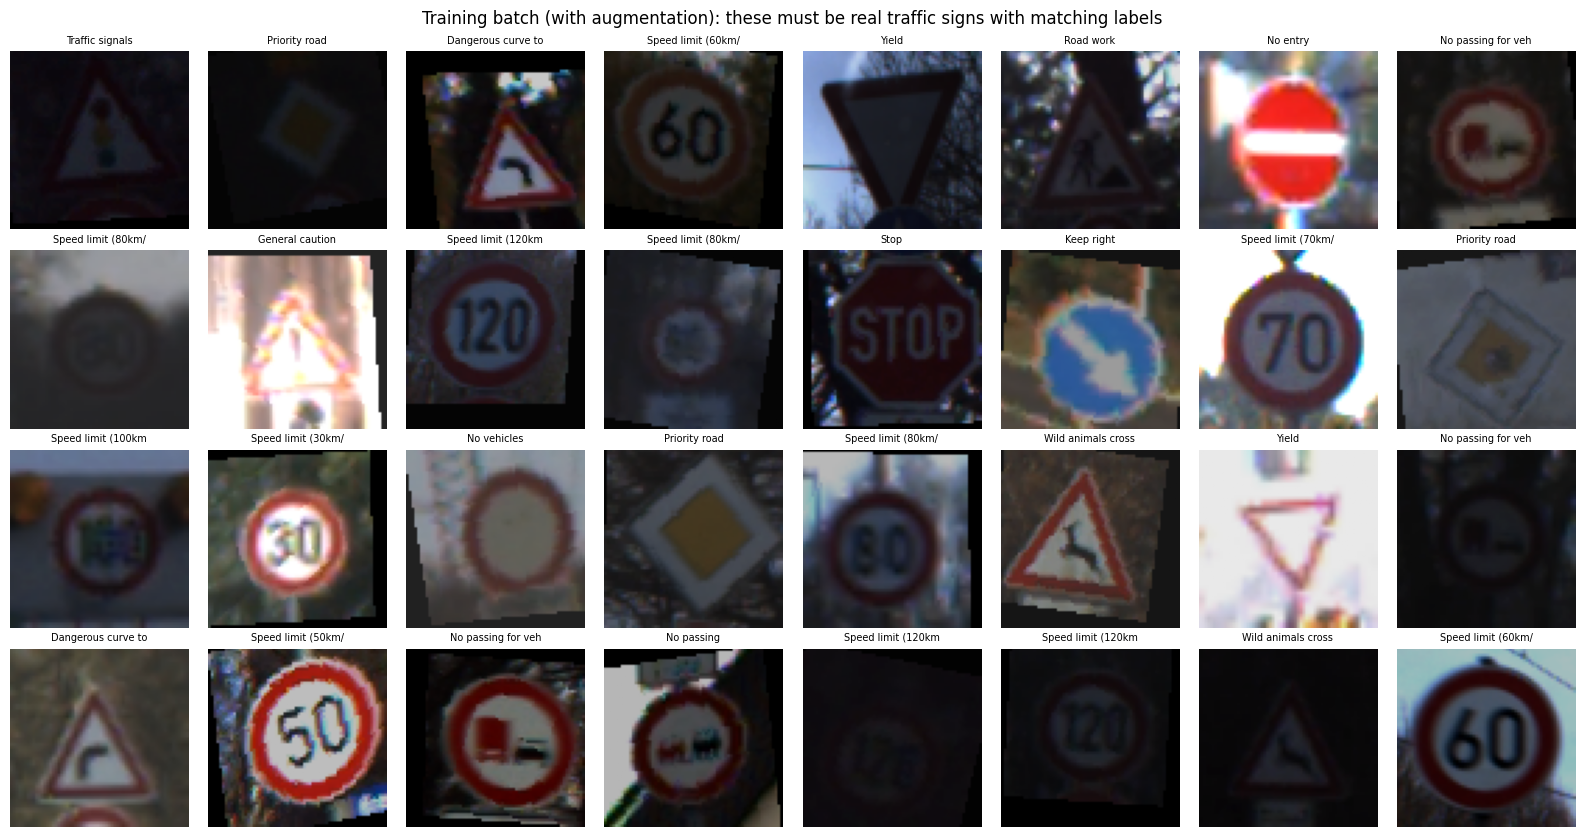

✅ Data checks passed


In [8]:
import numpy as np, torch, matplotlib.pyplot as plt
from collections import Counter
from common import CLASS_NAMES

assert len(te) > 10000, f"Test set has only {len(te)} images, so this is NOT the real GTSRB"
assert len(tr) > 20000, f"Train set has only {len(tr)} images, so this is NOT the real GTSRB"

rng = np.random.default_rng(0)
tr_labels = Counter(int(tr[int(i)][1]) for i in rng.choice(len(tr), 3000, replace=False))
te_labels = Counter(int(te[int(i)][1]) for i in rng.choice(len(te), 3000, replace=False))
print("distinct train labels in sample:", len(tr_labels), "| distinct test labels:", len(te_labels))
assert len(tr_labels) >= 40 and len(te_labels) >= 40, "Labels look broken (too few distinct classes)"

loader = torch.utils.data.DataLoader(tr, batch_size=64, shuffle=True)
x, y = next(iter(loader))
print("batch", tuple(x.shape), "min %.2f max %.2f mean %.3f" % (x.min(), x.max(), x.mean()))
assert x.shape[1:] == (3, 64, 64) and 0.5 < x.max() <= 1.0 and 0.05 < x.mean() < 0.8, "Image tensors look wrong"

fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
for ax, img, lab in zip(axes.ravel(), x[:32], y[:32]):
    ax.imshow(img.permute(1, 2, 0)); ax.set_title(CLASS_NAMES[lab][:18], fontsize=7); ax.axis("off")
plt.suptitle("Training batch (with augmentation): these must be real traffic signs with matching labels"); plt.tight_layout(); plt.show()
print("✅ Data checks passed")

## 6. EDA plots (saved to outputs/)

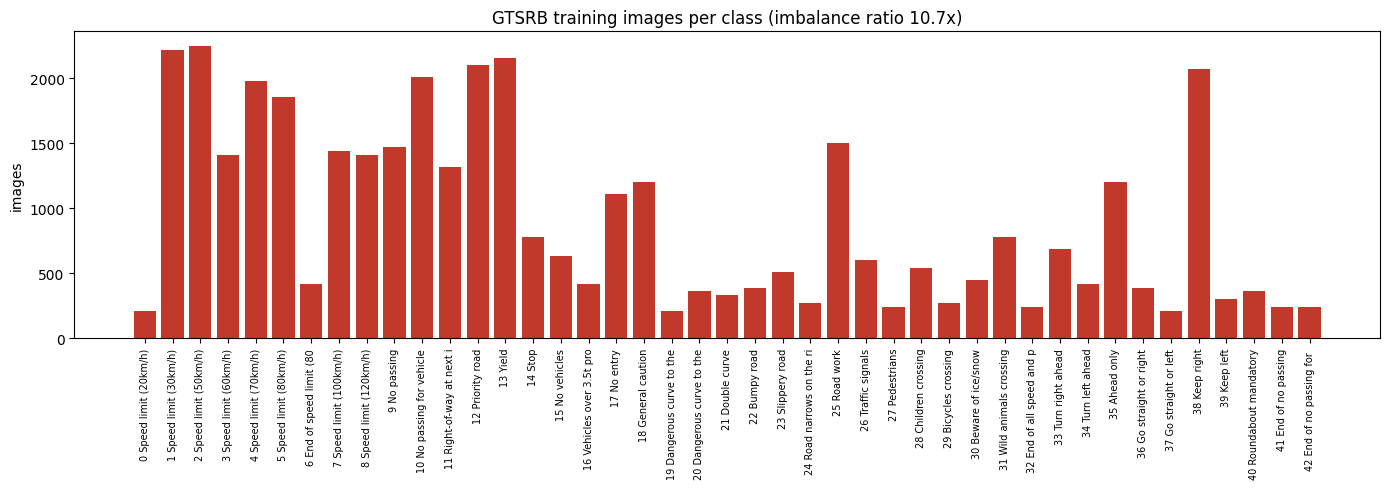

total 39209 | min/class 210 | max/class 2250


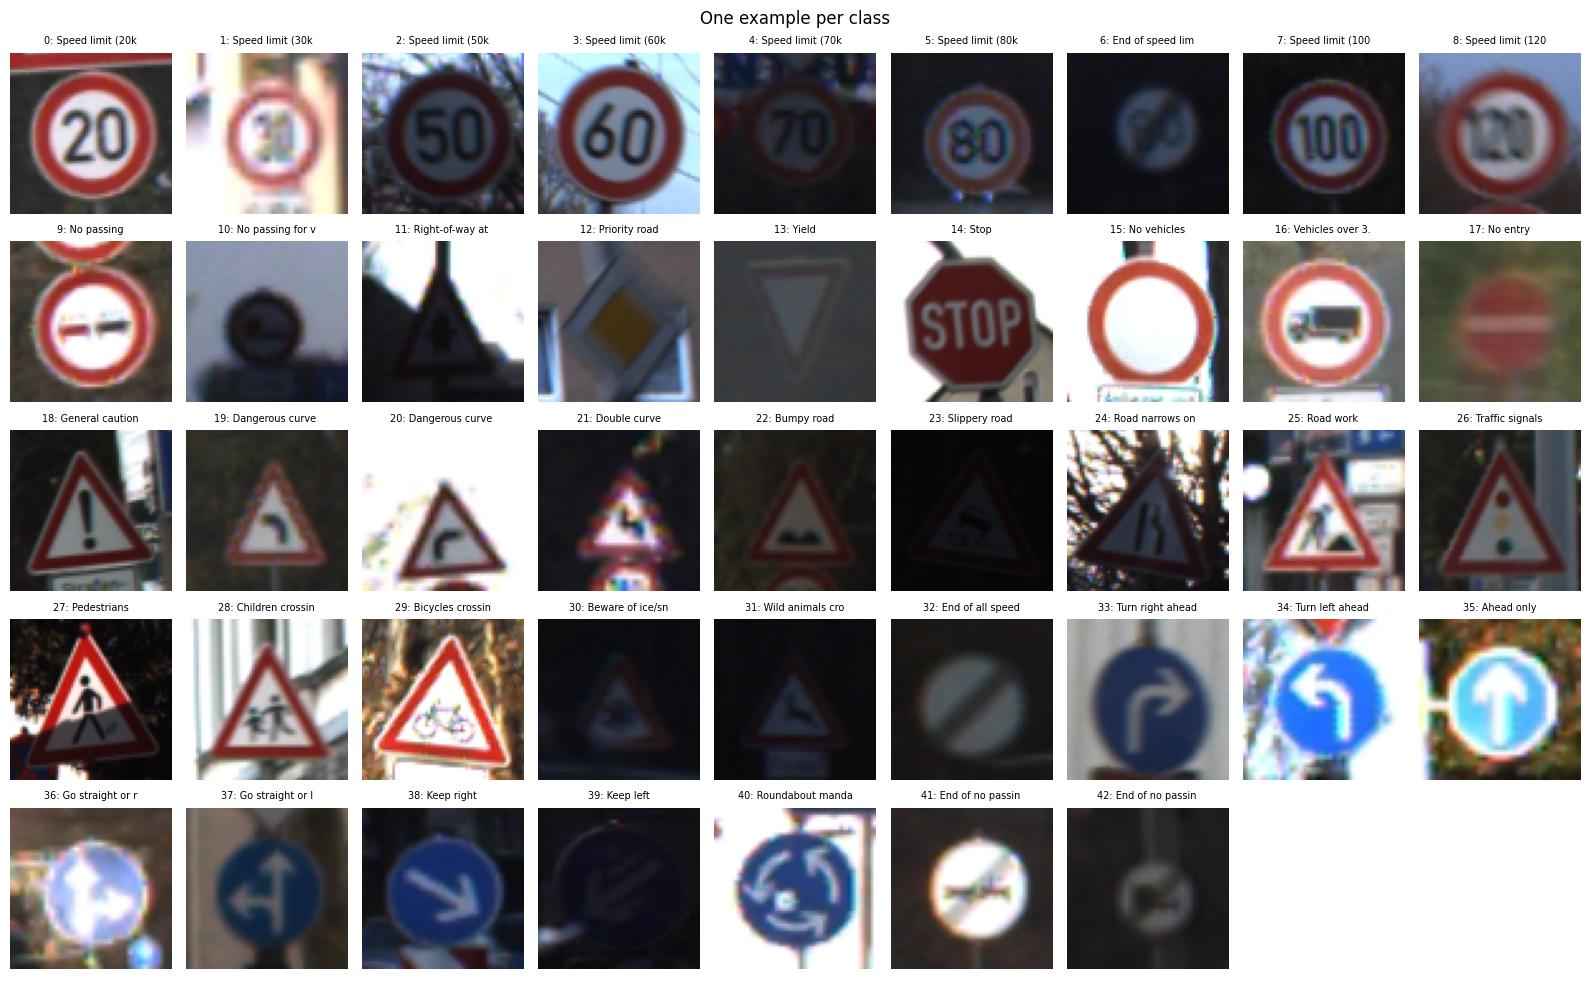

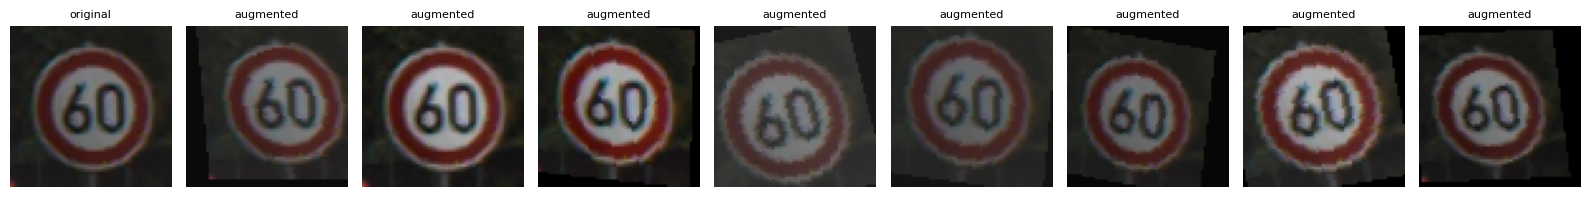

In [9]:
from common import get_transforms
from PIL import Image
os.makedirs("outputs", exist_ok=True)

# class distribution: read labels without loading images
base = tr.dataset
targets = [s[1] for s in base._samples] if hasattr(base, "_samples") else [base.target_transform(t) for t in base.targets]
cnt = Counter(targets)
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(range(43), [cnt[i] for i in range(43)], color="#c0392b")
ax.set_xticks(range(43)); ax.set_xticklabels([f"{i} {CLASS_NAMES[i][:22]}" for i in range(43)], rotation=90, fontsize=7)
ax.set_ylabel("images"); ax.set_title(f"GTSRB training images per class (imbalance ratio {max(cnt.values())/min(cnt.values()):.1f}x)")
fig.tight_layout(); fig.savefig("outputs/eda_class_distribution.png", dpi=130); plt.show()
print("total", len(targets), "| min/class", min(cnt.values()), "| max/class", max(cnt.values()))

# one sample per class
seen = {}
for i in rng.permutation(len(te)):
    _, lab = te[int(i)]
    if lab not in seen: seen[lab] = int(i)
    if len(seen) == 43: break
fig, axes = plt.subplots(5, 9, figsize=(16, 10))
for ax in axes.ravel(): ax.axis("off")
for ax, c in zip(axes.ravel(), range(43)):
    ax.imshow(te[seen[c]][0].permute(1, 2, 0)); ax.set_title(f"{c}: {CLASS_NAMES[c][:16]}", fontsize=7)
fig.suptitle("One example per class"); fig.tight_layout(); fig.savefig("outputs/eda_samples.png", dpi=130); plt.show()

# augmentation demo
raw = tr.dataset
img_path = raw._samples[tr.indices[0]][0] if hasattr(raw, "_samples") else raw.samples[tr.indices[0]][0]
pil = Image.open(img_path).convert("RGB")
aug = get_transforms(train=True)
fig, axes = plt.subplots(1, 9, figsize=(16, 2.4))
axes[0].imshow(pil.resize((64, 64))); axes[0].set_title("original", fontsize=8)
for ax in axes[1:]: ax.imshow(aug(pil).permute(1, 2, 0)); ax.set_title("augmented", fontsize=8)
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig("outputs/eda_augmentation.png", dpi=130); plt.show()

## 7. Train the 4 models
Watch the per-epoch lines: **val acc should pass ~0.8 within 2–3 epochs.** Old results are deleted first.

In [10]:
for f in ["outputs/metrics.json", "outputs/comparison.csv"]:
    if os.path.exists(f): os.remove(f)
ARGS = f"--source {SOURCE} --data {DATA} --workers 2 --batch-size 128"
print(ARGS)

--source folder --data /content/signsense/data/gtsrb --workers 2 --batch-size 128


In [11]:
!python train.py --models cnn --epochs-cnn 15 $ARGS

train 35289 | val 3920 | test 12630

=== Training cnn  (0.82M params) on cuda ===
ep 01/15 | train loss 3.7091 acc 0.1054 | val loss 2.6310 acc 0.3536 | 41s  *saved*
ep 02/15 | train loss 2.3486 acc 0.3771 | val loss 1.3372 acc 0.7074 | 36s  *saved*
ep 03/15 | train loss 1.2813 acc 0.7170 | val loss 0.6199 acc 0.9786 | 39s  *saved*
ep 04/15 | train loss 0.8147 acc 0.8969 | val loss 0.5457 acc 0.9916 | 37s  *saved*
ep 05/15 | train loss 0.6618 acc 0.9487 | val loss 0.4970 acc 0.9954 | 37s  *saved*
ep 06/15 | train loss 0.5961 acc 0.9682 | val loss 0.4739 acc 0.9985 | 37s  *saved*
ep 07/15 | train loss 0.5530 acc 0.9797 | val loss 0.4408 acc 0.9987 | 37s  *saved*
ep 08/15 | train loss 0.5268 acc 0.9861 | val loss 0.4335 acc 0.9992 | 37s  *saved*
ep 09/15 | train loss 0.5066 acc 0.9896 | val loss 0.4302 acc 1.0000 | 37s  *saved*
ep 10/15 | train loss 0.4974 acc 0.9904 | val loss 0.4201 acc 1.0000 | 36s  *saved*
ep 11/15 | train loss 0.4858 acc 0.9931 | val loss 0.4159 acc 1.0000 | 36s  *s

In [12]:
!python train.py --models resnet18 --epochs-resnet 8 $ARGS

train 35289 | val 3920 | test 12630
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 173MB/s]

=== Training resnet18  (11.20M params) on cuda ===
ep 01/8 | train loss 1.8691 acc 0.5482 | val loss 0.6709 acc 0.9207 | 36s  *saved*
ep 02/8 | train loss 0.5568 acc 0.9529 | val loss 0.4337 acc 0.9857 | 35s  *saved*
ep 03/8 | train loss 0.4510 acc 0.9837 | val loss 0.4350 acc 0.9842 | 35s
ep 04/8 | train loss 0.4200 acc 0.9922 | val loss 0.3907 acc 0.9969 | 34s  *saved*
ep 05/8 | train loss 0.4016 acc 0.9961 | val loss 0.3845 acc 0.9985 | 35s  *saved*
ep 06/8 | train loss 0.3927 acc 0.9984 | val loss 0.3804 acc 0.9995 | 34s  *saved*
ep 07/8 | train loss 0.3894 acc 0.9991 | val loss 0.3801 acc 0.9992 | 34s
ep 08/8 | train loss 0.3898 acc 0.9988 | val loss 0.3797 acc 0.9995 | 34s  *saved*
[resnet18] TEST accuracy 0.9899 | macro-F1 0.9831

model,params_M,MFLOPs,test_accuracy,macro_

In [13]:
!python train.py --models mobilenet --epochs-resnet 10 $ARGS

train 35289 | val 3920 | test 12630
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
100% 9.83M/9.83M [00:00<00:00, 48.3MB/s]

=== Training mobilenet  (1.56M params) on cuda ===
ep 01/10 | train loss 2.7343 acc 0.2880 | val loss 1.8511 acc 0.4987 | 37s  *saved*
ep 02/10 | train loss 1.0010 acc 0.7912 | val loss 0.6334 acc 0.9222 | 36s  *saved*
ep 03/10 | train loss 0.6135 acc 0.9305 | val loss 0.4994 acc 0.9699 | 36s  *saved*
ep 04/10 | train loss 0.5115 acc 0.9636 | val loss 0.4723 acc 0.9742 | 36s  *saved*
ep 05/10 | train loss 0.4662 acc 0.9791 | val loss 0.4378 acc 0.9857 | 36s  *saved*
ep 06/10 | train loss 0.4455 acc 0.9845 | val loss 0.4136 acc 0.9923 | 36s  *saved*
ep 07/10 | train loss 0.4273 acc 0.9892 | val loss 0.4015 acc 0.9957 | 37s  *saved*
ep 08/10 | train loss 0.4139 acc 0.9931 | val loss 0.3923 acc 0.9987 | 36s  *saved*
ep 09/10 | train loss 0.4082 acc 0.9951 | val 

In [14]:
!python train.py --models cnn_robust --epochs-cnn 15 --adv-eps 0.02 $ARGS

train 35289 | val 3920 | test 12630

=== Training cnn_robust  (0.82M params) on cuda, adversarial training eps=0.02 ===
ep 01/15 | train loss 3.6714 acc 0.1197 | val loss 2.5377 acc 0.3719 | 58s  *saved*
ep 02/15 | train loss 2.5194 acc 0.3859 | val loss 1.3274 acc 0.7301 | 56s  *saved*
ep 03/15 | train loss 1.6154 acc 0.7230 | val loss 0.6586 acc 0.9679 | 56s  *saved*
ep 04/15 | train loss 1.1288 acc 0.9011 | val loss 0.5493 acc 0.9931 | 56s  *saved*
ep 05/15 | train loss 0.8595 acc 0.9557 | val loss 0.4986 acc 0.9972 | 56s  *saved*
ep 06/15 | train loss 0.6672 acc 0.9780 | val loss 0.4568 acc 0.9990 | 56s  *saved*
ep 07/15 | train loss 0.5712 acc 0.9862 | val loss 0.4384 acc 0.9995 | 56s  *saved*
ep 08/15 | train loss 0.5323 acc 0.9906 | val loss 0.4289 acc 0.9995 | 56s  *saved*
ep 09/15 | train loss 0.5075 acc 0.9938 | val loss 0.4194 acc 1.0000 | 56s  *saved*
ep 10/15 | train loss 0.4916 acc 0.9949 | val loss 0.4156 acc 1.0000 | 56s  *saved*
ep 11/15 | train loss 0.4819 acc 0.9965 

## 8. Check the results

In [15]:
import json, pandas as pd
m = json.load(open("outputs/metrics.json"))
df = pd.DataFrame({k: {kk: v for kk, v in r.items() if kk not in ("history", "fgsm_accuracy")} | {"fgsm_acc_eps0.02": r["fgsm_accuracy"]["0.02"]} for k, r in m.items()}).T
display(df)
bad = [k for k, r in m.items() if r["test_accuracy"] < 0.9]
assert not bad, f"These models did not learn properly: {bad}. Scroll up to their training logs."
print("✅ All models above 90% test accuracy")
print("FGSM eps=0.02 -> cnn:", m["cnn"]["fgsm_accuracy"]["0.02"], "| cnn_robust:", m["cnn_robust"]["fgsm_accuracy"]["0.02"])

,params_M,MFLOPs,adversarial_training_eps,test_accuracy,macro_f1,best_val_accuracy,latency_ms_per_image,fgsm_acc_eps0.02
cnn,0.824,310.1,0.00,0.9959,0.9960,1.0000,0.999,0.8289
resnet18,11.199,296.1,0.00,0.9899,0.9831,0.9995,2.289,0.9461
mobilenet,1.562,11.1,0.00,0.9505,0.9302,0.9990,5.156,0.6406
cnn_robust,0.824,310.1,0.02,0.9969,0.9964,1.0000,1.037,0.9871


✅ All models above 90% test accuracy
FGSM eps=0.02 -> cnn: 0.8289 | cnn_robust: 0.9871


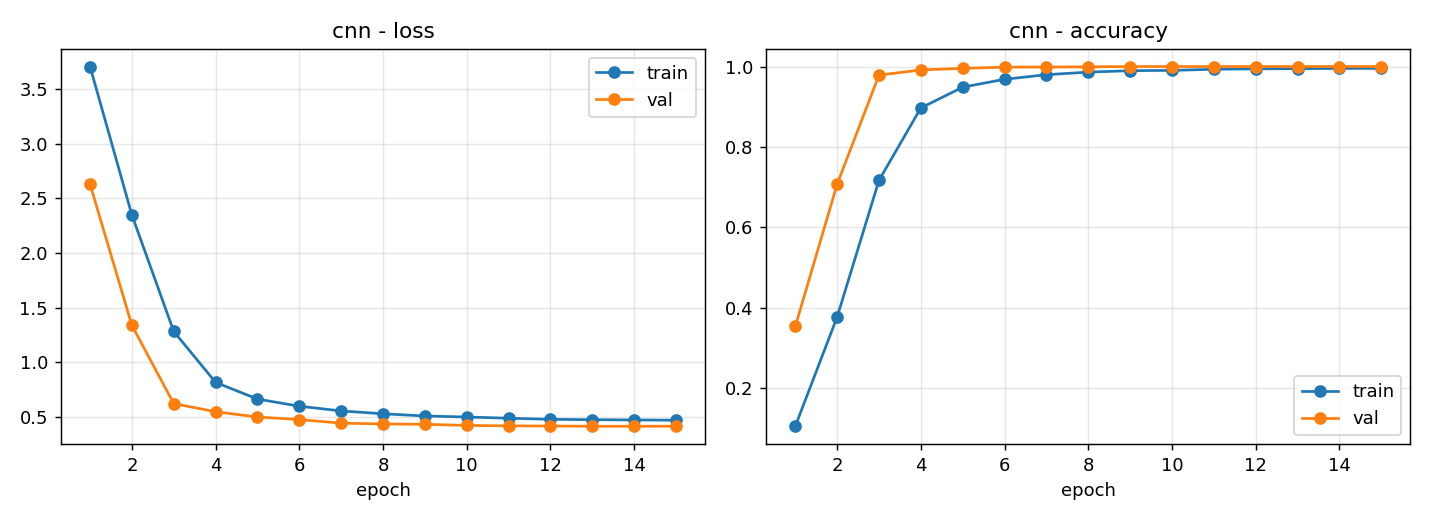

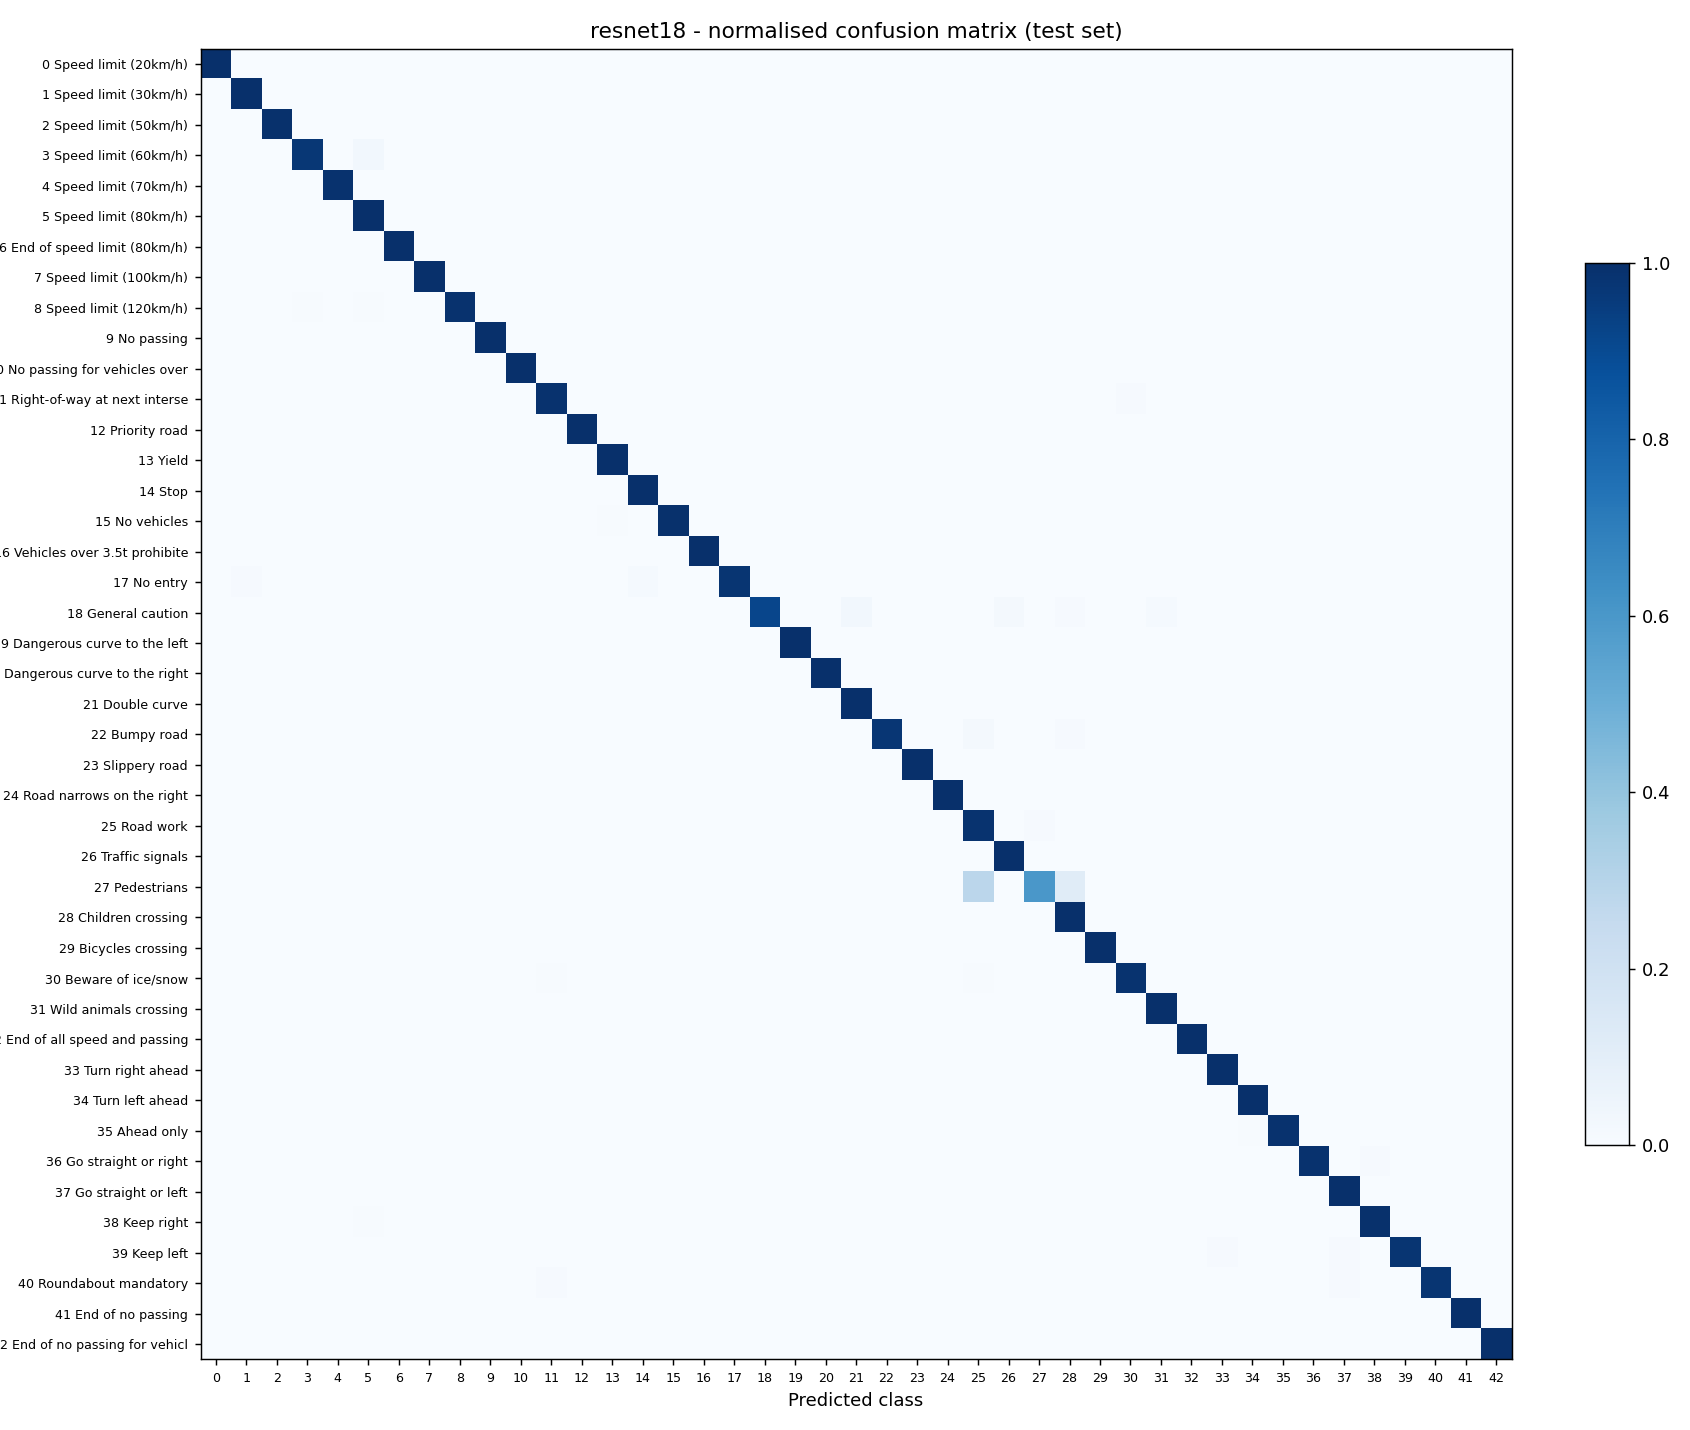

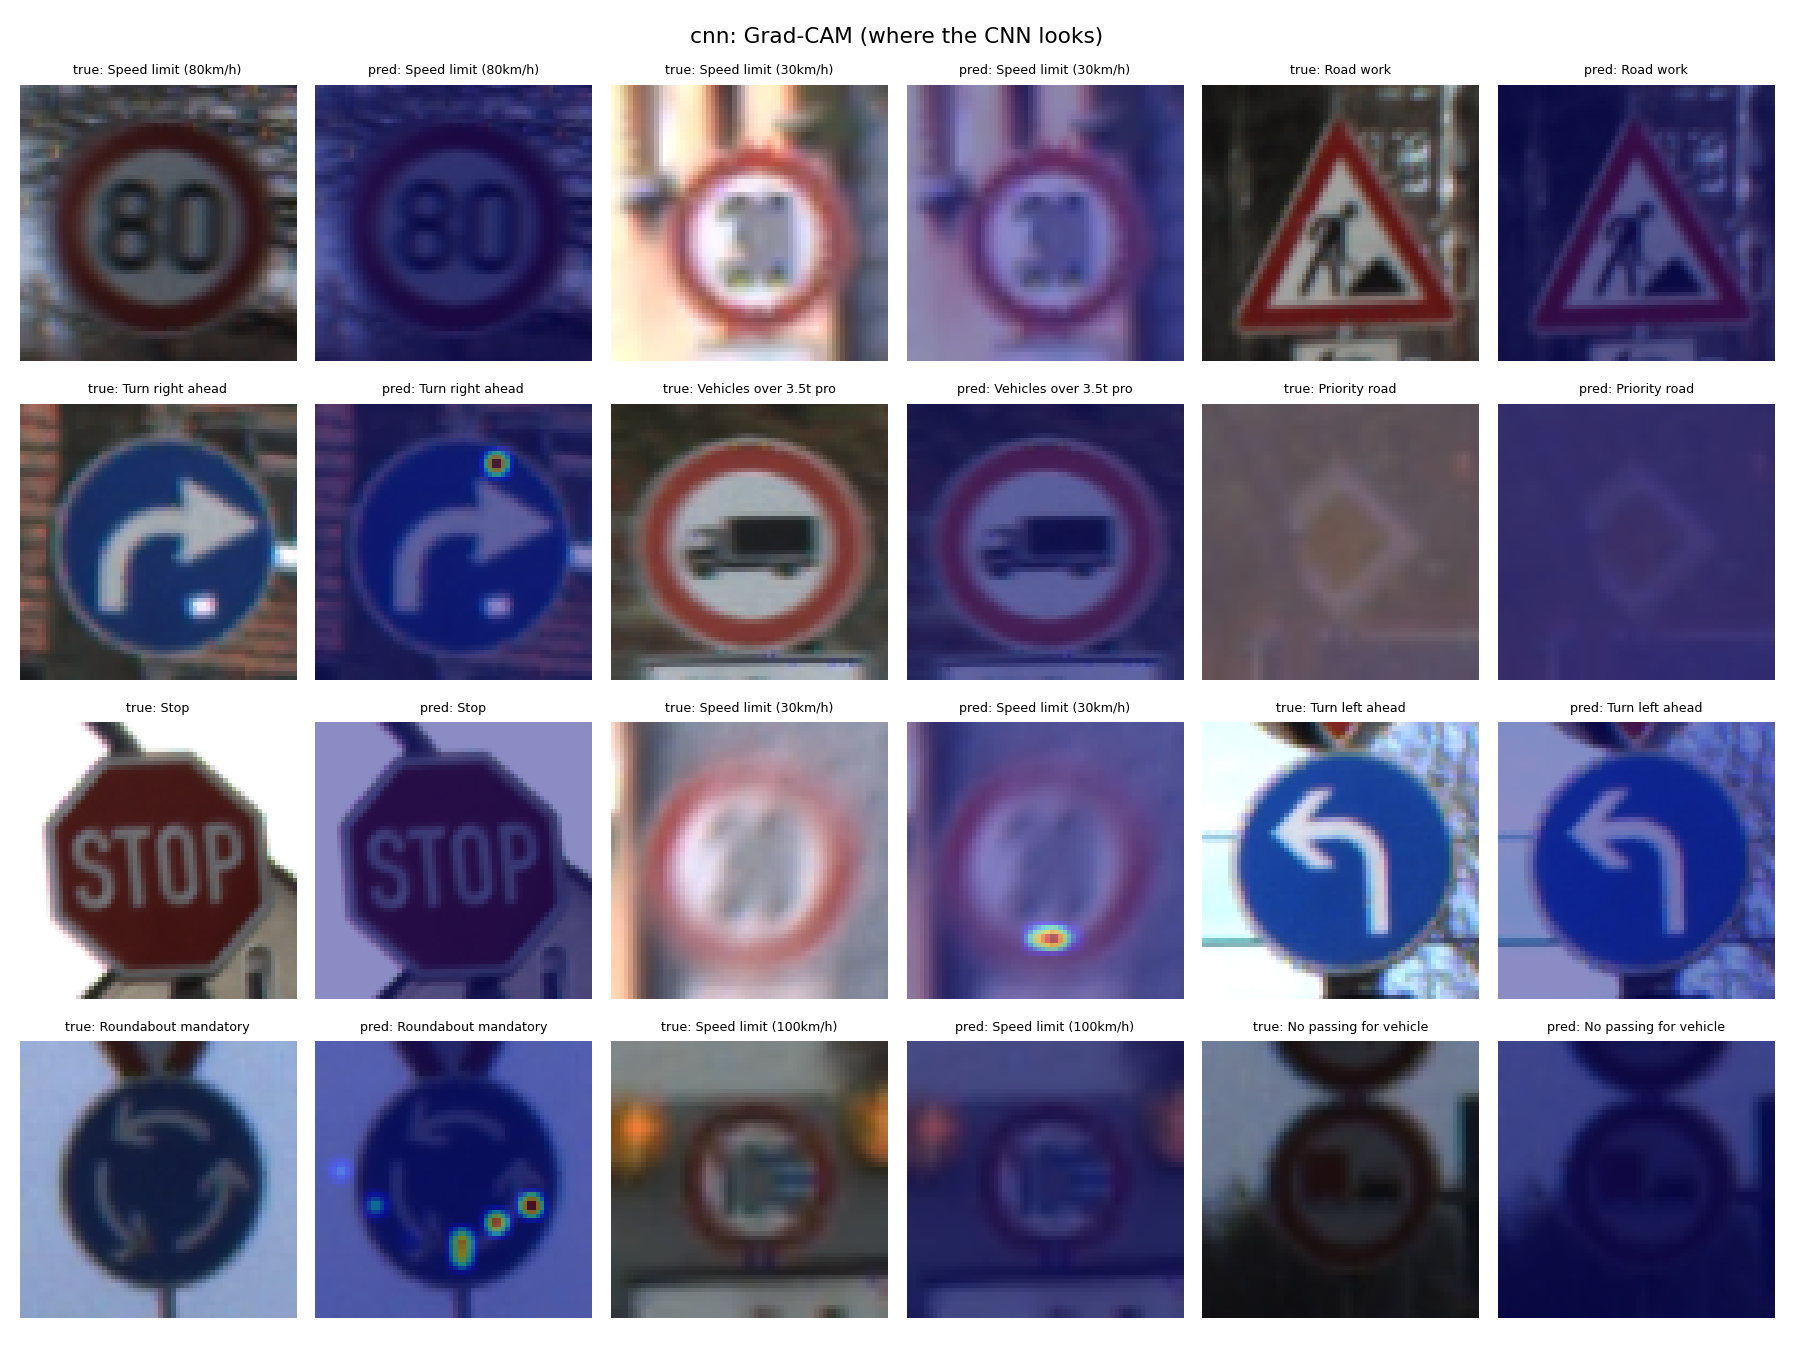

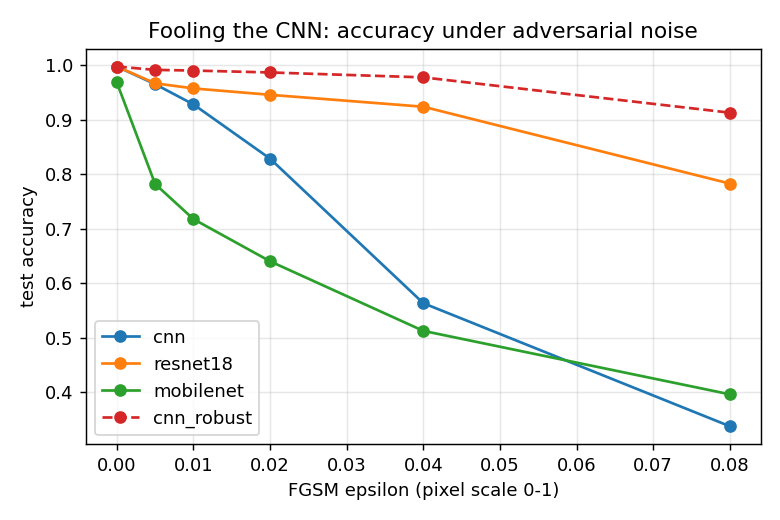

In [16]:
from IPython.display import Image as Img, display
for f in ["cnn_curves", "resnet18_confusion", "cnn_gradcam", "fgsm_robustness"]:
    display(Img(f"outputs/{f}.png", width=900))

## 9. Edge deployment benchmark (ONNX)

/content/signsense/export_onnx.py:44: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, (x,), path, input_names=["image"], output_names=["logits"],
cnn          onnx   3.30 MB | torch   7.00 ms | onnxruntime   2.93 ms | speed-up x2.39 | max |diff| 1.2e-06
cnn_robust   onnx   3.30 MB | torch   7.17 ms | onnxruntime   2.79 ms | speed-up x2.57 | max |diff| 1.3e-06
mobilenet    onnx   6.26 MB | torch   5.87 ms | onnxruntime   0.74 ms | speed-up x7.94 | max |diff| 3.1e-06
resnet18     onnx  44.79 MB | torch  13.62 ms | onnxruntime   5.21 ms | speed-up x2.62 | max |diff| 9.5e-07
saved outputs/onnx_benchmark.csv


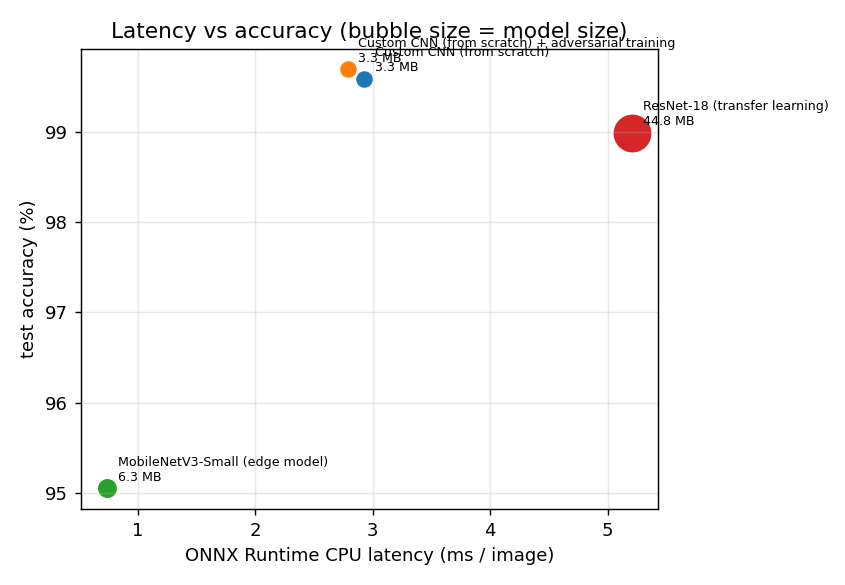

In [17]:
!python export_onnx.py
display(Img('outputs/latency_vs_accuracy.png', width=600))

## 10. Package and download the results
Downloads `signsense_results.zip` (~60 MB): models (.pt), outputs (plots + metrics), samples, and the exact code used.

In [18]:
!rm -f signsense_results.zip
!zip -rq signsense_results.zip models/*.pt outputs samples src/common.py train.py export_onnx.py
!ls -lh signsense_results.zip
from google.colab import files
files.download("signsense_results.zip")

-rw-r--r-- 1 root root 55M Oct 26 16:02 signsense_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>